In [1]:
!pip install -q kagglehub

In [2]:
import kagglehub
import os
import tensorflow as tf

dataset_path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")

DATA_DIR = os.path.join(dataset_path, "Garbage classification", "Garbage classification")

print(f"Checking: {DATA_DIR}")
print(f"Exists: {os.path.exists(DATA_DIR)}")

if os.path.exists(DATA_DIR):
    print(f"\nContents: {os.listdir(DATA_DIR)[:10]}")

    full_dataset = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.3,
        subset="training",
        seed=42,
        image_size=(224, 224),
        batch_size=32,
        label_mode='categorical'
    )

    print(f"\nClass names: {full_dataset.class_names}")
else:
    print("Path not found. Running full search...")

    for root, dirs, files in os.walk(dataset_path):
        if 'cardboard' in [d.lower() for d in dirs]:
            print(f"\n Found class folders in: {root}")
            print(f"Classes: {[d for d in dirs if d.lower() in ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']]}")
            DATA_DIR = root
            break

    if DATA_DIR:
        full_dataset = tf.keras.utils.image_dataset_from_directory(
            DATA_DIR,
            validation_split=0.3,
            subset="training",
            seed=42,
            image_size=(224, 224),
            batch_size=32,
            label_mode='categorical'
        )

Using Colab cache for faster access to the 'garbage-classification' dataset.
Checking: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
Exists: True

Contents: ['metal', 'glass', 'paper', 'trash', 'cardboard', 'plastic']
Found 2527 files belonging to 6 classes.
Using 1769 files for training.

Class names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import os
from datetime import datetime

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 6
EPOCHS = 20
LEARNING_RATE = 0.001
SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:

full_dataset = tf.keras.utils.image_dataset_from_directory(
    "/kaggle/input/garbage-classification/Garbage classification/Garbage classification",
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = full_dataset.class_names
print(f"\nClasses: {class_names}")
print(f"Number of classes: {len(class_names)}")

Found 2527 files belonging to 6 classes.
Using 1769 files for training.

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 6


In [5]:
file_paths = []
labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join("/kaggle/input/garbage-classification/Garbage classification/Garbage classification", class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

print(f"Total images: {len(file_paths)}")

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths, labels, test_size=0.3, stratify=labels, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED
)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

def print_distribution(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"{name}: {dict(zip([class_names[i] for i in unique], counts))}")

print_distribution(y_train, "Train")
print_distribution(y_val, "Val")
print_distribution(y_test, "Test")

Total images: 2527
Train: 1768, Val: 379, Test: 380
Train: {'cardboard': np.int64(282), 'glass': np.int64(350), 'metal': np.int64(287), 'paper': np.int64(416), 'plastic': np.int64(337), 'trash': np.int64(96)}
Val: {'cardboard': np.int64(61), 'glass': np.int64(75), 'metal': np.int64(61), 'paper': np.int64(89), 'plastic': np.int64(72), 'trash': np.int64(21)}
Test: {'cardboard': np.int64(60), 'glass': np.int64(76), 'metal': np.int64(62), 'paper': np.int64(89), 'plastic': np.int64(73), 'trash': np.int64(20)}


In [6]:
def preprocess_image(image_path, label):
    image_path = tf.strings.join(["/kaggle/input/garbage-classification/Garbage classification/Garbage classification/", image_path])
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.rot90(image, k=tf.random.uniform(shape=[], minval=1, maxval=4, dtype=tf.int32))
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    return image, label

def create_dataset(file_paths, labels, batch_size, augment_flag=False):
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

    if augment_flag:
        dataset = dataset.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_dataset = create_dataset(X_train, y_train, BATCH_SIZE, augment_flag=True)
val_dataset = create_dataset(X_val, y_val, BATCH_SIZE, augment_flag=False)
test_dataset = create_dataset(X_test, y_test, BATCH_SIZE, augment_flag=False)

# One-hot encode labels (they're currently integers)
def one_hot(image, label):
    return image, tf.one_hot(label, depth=NUM_CLASSES)

train_dataset = train_dataset.map(one_hot)
val_dataset = val_dataset.map(one_hot)
test_dataset = test_dataset.map(one_hot)

# Test the pipeline
for images, labels in train_dataset.take(1):
    print(f"Train batch - Images: {images.shape}, Labels: {labels.shape}")

Train batch - Images: (32, 224, 224, 3), Labels: (32, 6)


In [7]:
from tensorflow.keras import layers, models

def build_mobilenetv2():
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    return model

print("Building MobileNetV2...")
mobilenet_model = build_mobilenetv2()
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_model.summary()

Building MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
def build_resnet50v2():
    base_model = tf.keras.applications.ResNet50V2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    return model

# Build and compile
print("Building ResNet50V2...")
resnet_model = build_resnet50v2()
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

resnet_model.summary()

Building ResNet50V2...
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,577,094 (89.94 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [9]:
# Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Train
print("="*60)
print("Training MobileNetV2")
print("="*60)

history_mobilenet = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Training MobileNetV2
Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 87s 738ms/step - accuracy: 0.4876 - loss: 1.3530 - val_accuracy: 0.6781 - val_loss: 0.8653 - learning_rate: 0.0010
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.7059 - loss: 0.7723 - val_accuracy: 0.7335 - val_loss: 0.7222 - learning_rate: 0.0010
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.7596 - loss: 0.6533 - val_accuracy: 0.7573 - val_loss: 0.6561 - learning_rate: 0.0010
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.7851 - loss: 0.5762 - val_accuracy: 0.7678 - val_loss: 0.6097 - learning_rate: 0.0010
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.7964 - loss: 0.5308 - val_accuracy: 0.7810 - val_loss: 0.5803 - learning_rate: 0.0010
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.8252 - loss: 0.4762 - val_accuracy: 0.7757 - val_loss: 0.5619 - learning_rate: 0.0010
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.8382 -

In [10]:
# Reset callbacks for ResNet
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("="*60)
print("Training ResNet50V2")
print("="*60)

history_resnet = resnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Training ResNet50V2
Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 407ms/step - accuracy: 0.5724 - loss: 1.1874 - val_accuracy: 0.7467 - val_loss: 0.7060 - learning_rate: 0.0010
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.7619 - loss: 0.6577 - val_accuracy: 0.8074 - val_loss: 0.6032 - learning_rate: 0.0010
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.7981 - loss: 0.5347 - val_accuracy: 0.8179 - val_loss: 0.5538 - learning_rate: 0.0010
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.8298 - loss: 0.4408 - val_accuracy: 0.8232 - val_loss: 0.5094 - learning_rate: 0.0010
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8637 - loss: 0.3823 - val_accuracy: 0.8232 - val_loss: 0.5064 - learning_rate: 0.0010
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.8778 - loss: 0.3474 - val_accuracy: 0.8259 - val_loss: 0.4839 - learning_rate: 0.0010
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.8840


Evaluating MobileNetV2

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.98      0.93      0.96        60
       glass       0.82      0.88      0.85        76
       metal       0.86      0.82      0.84        62
       paper       0.86      0.90      0.88        89
     plastic       0.74      0.74      0.74        73
       trash       0.75      0.60      0.67        20

    accuracy                           0.84       380
   macro avg       0.84      0.81      0.82       380
weighted avg       0.84      0.84      0.84       380



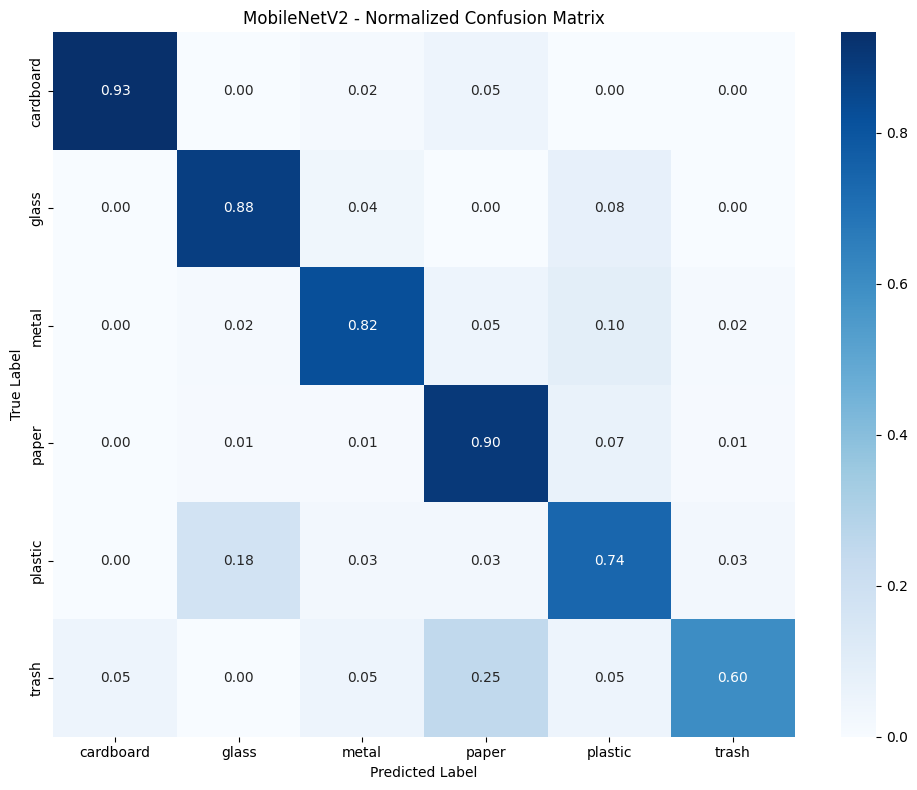


Evaluating ResNet50V2

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.90      0.93      0.92        60
       glass       0.81      0.87      0.84        76
       metal       0.82      0.76      0.79        62
       paper       0.88      0.90      0.89        89
     plastic       0.79      0.79      0.79        73
       trash       0.69      0.55      0.61        20

    accuracy                           0.84       380
   macro avg       0.82      0.80      0.81       380
weighted avg       0.83      0.84      0.83       380



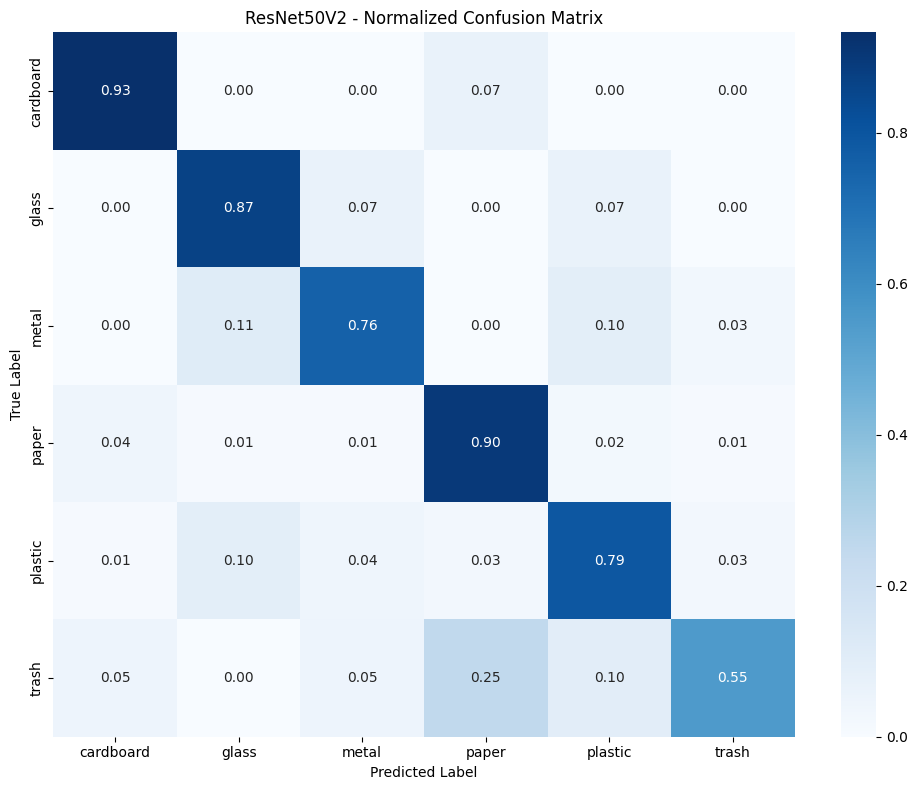


 Summary:
MobileNetV2 Macro F1: 0.8223
ResNet50V2 Macro F1: 0.8072


In [11]:
def evaluate_model(model, test_dataset, model_name):
    print(f"\n{'='*60}")
    print(f"Evaluating {model_name}")
    print('='*60)

    y_true = []
    y_pred = []

    for images, labels in test_dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} - Normalized Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

    # Calculate macro F1
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    macro_f1 = report['macro avg']['f1-score']

    return macro_f1, y_true, y_pred

# Evaluate both models
mobilenet_f1, _, _ = evaluate_model(mobilenet_model, test_dataset, "MobileNetV2")
resnet_f1, _, _ = evaluate_model(resnet_model, test_dataset, "ResNet50V2")

print(f"\n Summary:")
print(f"MobileNetV2 Macro F1: {mobilenet_f1:.4f}")
print(f"ResNet50V2 Macro F1: {resnet_f1:.4f}")

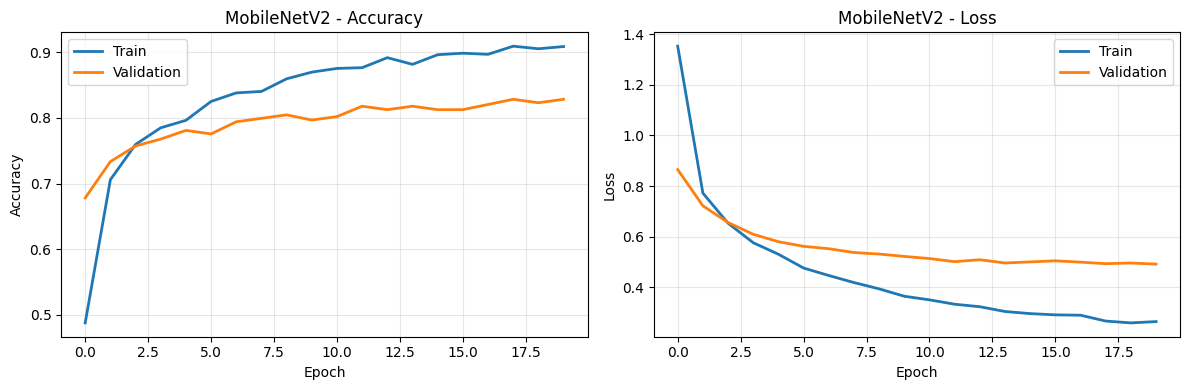

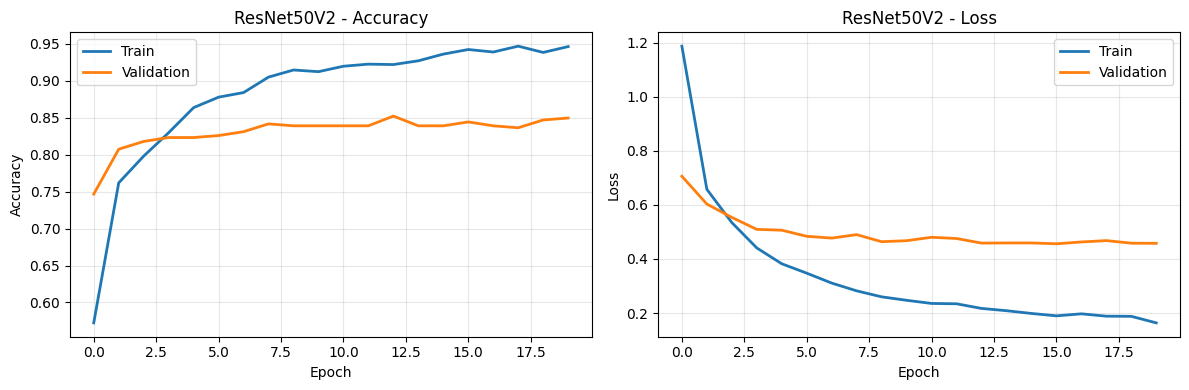

In [12]:
def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title(f'{model_name} - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title(f'{model_name} - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Plot both models
plot_training_history(history_mobilenet, "MobileNetV2")
plot_training_history(history_resnet, "ResNet50V2")

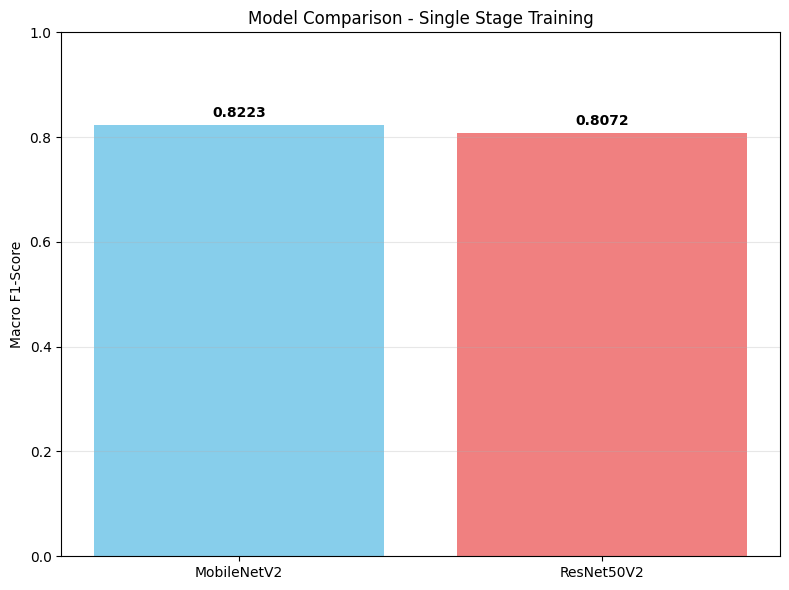


 Baseline Results Summary:
MobileNetV2: 0.8223 Macro F1
ResNet50V2: 0.8072 Macro F1


In [13]:
models = ['MobileNetV2', 'ResNet50V2']
f1_scores = [mobilenet_f1, resnet_f1]

plt.figure(figsize=(8, 6))
bars = plt.bar(models, f1_scores, color=['skyblue', 'lightcoral'])
plt.ylabel('Macro F1-Score')
plt.title('Model Comparison - Single Stage Training')
plt.ylim(0, 1)

for bar, score in zip(bars, f1_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{score:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\n Baseline Results Summary:")
print(f"MobileNetV2: {mobilenet_f1:.4f} Macro F1")
print(f"ResNet50V2: {resnet_f1:.4f} Macro F1")

In [14]:
!pip install -q tensorflow_hub transformers torch

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from transformers import ViTModel
import torch
import os

print(" Imports ready")
print(f"TensorFlow: {tf.__version__}")

 Imports ready
TensorFlow: 2.20.0


In [15]:
from sklearn.model_selection import train_test_split

DATA_DIR =  "/kaggle/input/garbage-classification/Garbage classification/Garbage classification"
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
NUM_CLASSES = 6
IMG_SIZE = 224

file_paths = []
labels = []
for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

print(f"Total images: {len(file_paths)}")

X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths, labels, test_size=0.3, stratify=labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Total images: 2527
Train: 1768, Val: 379, Test: 380


In [16]:
def preprocess_for_vit(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment_vit(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.rot90(image, tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32))
    return image, label

BATCH_SIZE_VIT = 16

def create_vit_dataset(file_paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    dataset = dataset.map(preprocess_for_vit, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_vit, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_dataset_vit = create_vit_dataset(X_train, y_train, BATCH_SIZE_VIT, augment=True)
val_dataset_vit   = create_vit_dataset(X_val,   y_val,   BATCH_SIZE_VIT, augment=False)
test_dataset_vit  = create_vit_dataset(X_test,  y_test,  BATCH_SIZE_VIT, augment=False)

for images, labels_batch in train_dataset_vit.take(1):
    print(f"ViT Input shape: {images.shape}")
    print(f"Value range: [{tf.reduce_min(images):.2f}, {tf.reduce_max(images):.2f}]")

ViT Input shape: (16, 224, 224, 3)
Value range: [0.00, 1.00]


In [17]:
import keras
import numpy as np

# Load PyTorch weights from HuggingFace
print("Loading pretrained weights from HuggingFace...")
pt_model = ViTModel.from_pretrained('google/vit-base-patch16-224')
pt_model.eval()
pt_weights = {name: param.detach().numpy() for name, param in pt_model.named_parameters()}
print(f" Loaded {len(pt_weights)} weight tensors")

# Native Keras ViT-B/16
def mlp_block(x, hidden_dim, out_dim, name):
    x = keras.layers.Dense(hidden_dim, activation='gelu', name=f"{name}_fc1")(x)
    x = keras.layers.Dense(out_dim, name=f"{name}_fc2")(x)
    return x

def attention_block(x, num_heads, head_dim, embed_dim, name):
    q = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_q")(x)
    k = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_k")(x)
    v = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_v")(x)

    q = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_q_reshape")(q)
    k = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_k_reshape")(k)
    v = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_v_reshape")(v)

    q = keras.layers.Permute((2, 1, 3), name=f"{name}_q_perm")(q)
    k = keras.layers.Permute((2, 1, 3), name=f"{name}_k_perm")(k)
    v = keras.layers.Permute((2, 1, 3), name=f"{name}_v_perm")(v)

    scale = head_dim ** -0.5
    attn = keras.layers.Lambda(
        lambda qk: keras.ops.softmax(
            keras.ops.matmul(qk[0], keras.ops.transpose(qk[1], (0, 1, 3, 2))) * scale,
            axis=-1
        ),
        name=f"{name}_attn_scores"
    )([q, k])

    out = keras.layers.Lambda(
        lambda av: keras.ops.matmul(av[0], av[1]),
        name=f"{name}_attn_out"
    )([attn, v])

    out = keras.layers.Permute((2, 1, 3), name=f"{name}_out_perm")(out)
    out = keras.layers.Reshape((-1, embed_dim), name=f"{name}_out_reshape")(out)
    out = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_proj")(out)
    return out

def transformer_block(x, num_heads=12, embed_dim=768, mlp_dim=3072, name="block"):
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    y = attention_block(y, num_heads=num_heads, head_dim=embed_dim // num_heads,
                        embed_dim=embed_dim, name=f"{name}_attn")
    x = keras.layers.Add()([x, y])
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    y = mlp_block(y, hidden_dim=mlp_dim, out_dim=embed_dim, name=f"{name}_mlp")
    x = keras.layers.Add()([x, y])
    return x

def build_vit_model(num_classes=6, learning_rate=2e-5,
                    image_size=224, patch_size=16, embed_dim=768,
                    num_heads=12, mlp_dim=3072, num_layers=12):
    num_patches = (image_size // patch_size) ** 2  # 196
    seq_len = num_patches + 1                       # 197

    inputs = keras.Input(shape=(image_size, image_size, 3), name="pixel_values")

    # Patch embedding
    patches = keras.layers.Conv2D(
        filters=embed_dim, kernel_size=patch_size, strides=patch_size,
        padding='valid', use_bias=True, name="patch_embed_proj"
    )(inputs)
    patches = keras.layers.Reshape((num_patches, embed_dim), name="patch_embed_reshape")(patches)

    # CLS token as a proper learned variable
    class CLSToken(keras.layers.Layer):
        def build(self, input_shape):
            self.cls = self.add_weight(
                name="cls", shape=(1, 1, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, embed_dim))

    cls_tokens = CLSToken(name="cls_token")(patches)
    x = keras.layers.Concatenate(axis=1, name="cls_concat")([cls_tokens, patches])

    # Positional embedding as a proper learned variable
    class PosEmbed(keras.layers.Layer):
        def build(self, input_shape):
            self.pos = self.add_weight(
                name="pos", shape=(1, seq_len, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return x + self.pos

    x = PosEmbed(name="pos_embed")(x)

    # Transformer blocks
    for i in range(num_layers):
        x = transformer_block(x, num_heads=num_heads, embed_dim=embed_dim,
                               mlp_dim=mlp_dim, name=f"block_{i}")

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln_final")(x)
    cls_out = keras.layers.Lambda(lambda t: t[:, 0, :], name="cls_extract")(x)

    z = keras.layers.Dense(256, activation='relu', name="head_dense")(cls_out)
    z = keras.layers.Dropout(0.3, name="head_dropout")(z)
    outputs = keras.layers.Dense(num_classes, name="head_out")(z)

    return keras.Model(inputs=inputs, outputs=outputs)

print("Building native Keras ViT-B/16...")
vit_model = build_vit_model(num_classes=NUM_CLASSES)

print("Transferring pretrained weights...")

def get_pt(key):
    return pt_weights[key]

vit_model.get_layer("patch_embed_proj").set_weights([
    np.transpose(get_pt("embeddings.patch_embeddings.projection.weight"), (2, 3, 1, 0)),
    get_pt("embeddings.patch_embeddings.projection.bias")
])
vit_model.get_layer("cls_token").set_weights([
    get_pt("embeddings.cls_token").reshape(1, 1, 768)
])
vit_model.get_layer("pos_embed").set_weights([
    get_pt("embeddings.position_embeddings").reshape(1, 197, 768)
])

for i in range(12):
    p = f"layers.{i}"
    vit_model.get_layer(f"block_{i}_ln1").set_weights([
        get_pt(f"{p}.layernorm_before.weight"),
        get_pt(f"{p}.layernorm_before.bias")
    ])
    vit_model.get_layer(f"block_{i}_attn_q").set_weights([
        get_pt(f"{p}.attention.q_proj.weight").T,
        get_pt(f"{p}.attention.q_proj.bias")
    ])
    vit_model.get_layer(f"block_{i}_attn_k").set_weights([
        get_pt(f"{p}.attention.k_proj.weight").T,
        get_pt(f"{p}.attention.k_proj.bias")
    ])
    vit_model.get_layer(f"block_{i}_attn_v").set_weights([
        get_pt(f"{p}.attention.v_proj.weight").T,
        get_pt(f"{p}.attention.v_proj.bias")
    ])
    vit_model.get_layer(f"block_{i}_attn_proj").set_weights([
        get_pt(f"{p}.attention.o_proj.weight").T,
        get_pt(f"{p}.attention.o_proj.bias")
    ])
    vit_model.get_layer(f"block_{i}_ln2").set_weights([
        get_pt(f"{p}.layernorm_after.weight"),
        get_pt(f"{p}.layernorm_after.bias")
    ])
    vit_model.get_layer(f"block_{i}_mlp_fc1").set_weights([
        get_pt(f"{p}.mlp.fc1.weight").T,
        get_pt(f"{p}.mlp.fc1.bias")
    ])
    vit_model.get_layer(f"block_{i}_mlp_fc2").set_weights([
        get_pt(f"{p}.mlp.fc2.weight").T,
        get_pt(f"{p}.mlp.fc2.bias")
    ])

vit_model.get_layer("ln_final").set_weights([
    get_pt("layernorm.weight"),
    get_pt("layernorm.bias")
])
print(" Pretrained weights transferred")

backbone_layers = [l for l in vit_model.layers if not l.name.startswith("head_")]
for layer in backbone_layers:
    layer.trainable = False

vit_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

trainable = sum([tf.size(v).numpy() for v in vit_model.trainable_variables])
non_trainable = sum([tf.size(v).numpy() for v in vit_model.non_trainable_variables])
print(f"Trainable:     {trainable:,}")
print(f"Non-trainable: {non_trainable:,}")
print(f"Total:         {trainable + non_trainable:,}")

Loading pretrained weights from HuggingFace...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 Loaded 200 weight tensors
Building native Keras ViT-B/16...
Transferring pretrained weights...
 Pretrained weights transferred
Trainable:     198,406
Non-trainable: 85,798,658
Total:         85,997,064


In [18]:
# Callbacks for ViT
early_stopping_vit = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_vit = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)
# Train
print("="*60)
print("Training Vision Transformer (ViT) - Single Stage")
print("="*60)
history_vit = vit_model.fit(
    train_dataset_vit,
    validation_data=val_dataset_vit,
    epochs=20,  # ViT typically needs fewer epochs due to pre-training
    callbacks=[early_stopping_vit, reduce_lr_vit],
    verbose=1
)

Training Vision Transformer (ViT) - Single Stage
Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 87s 400ms/step - accuracy: 0.3015 - loss: 1.8269 - val_accuracy: 0.4802 - val_loss: 1.3437 - learning_rate: 2.0000e-05
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 26s 237ms/step - accuracy: 0.4893 - loss: 1.3384 - val_accuracy: 0.6517 - val_loss: 1.0157 - learning_rate: 2.0000e-05
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 27s 245ms/step - accuracy: 0.6137 - loss: 1.0622 - val_accuracy: 0.7309 - val_loss: 0.8231 - learning_rate: 2.0000e-05
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 29s 257ms/step - accuracy: 0.6736 - loss: 0.8857 - val_accuracy: 0.7625 - val_loss: 0.7085 - learning_rate: 2.0000e-05
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 28s 249ms/step - accuracy: 0.7285 - loss: 0.7611 - val_accuracy: 0.8100 - val_loss: 0.6339 - learning_rate: 2.0000e-05
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 28s 248ms/step - accuracy: 0.7636 - loss: 0.6893 - val_accuracy: 0.8285 - val_loss: 0.5795 - learning_rate: 2.0000e-


Evaluating Vision Transformer (ViT)

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.93      0.90      0.92        60
       glass       0.91      0.95      0.93        76
       metal       0.90      0.89      0.89        62
       paper       0.89      0.94      0.92        89
     plastic       0.84      0.78      0.81        73
       trash       0.60      0.60      0.60        20

    accuracy                           0.88       380
   macro avg       0.85      0.84      0.84       380
weighted avg       0.88      0.88      0.88       380



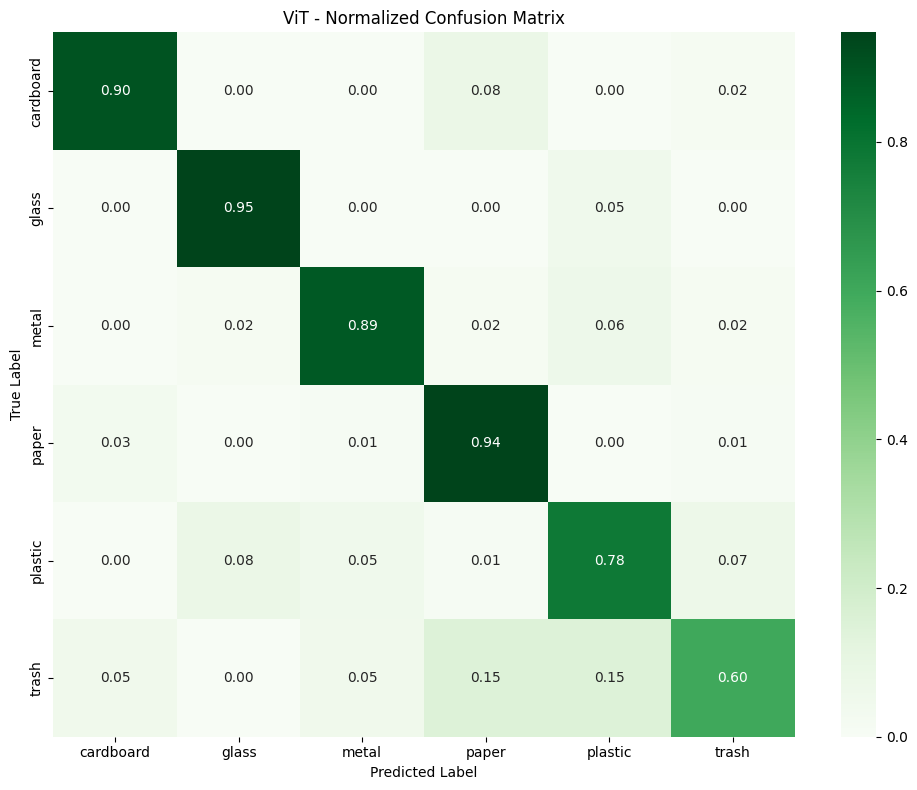


 ViT Macro F1: 0.8442

 ViT Per-Class F1:
  cardboard: 0.9153
  glass: 0.9290
  metal: 0.8943
  paper: 0.9180
  plastic: 0.8085
  trash: 0.6000


In [19]:
def evaluate_vit(model, test_dataset, class_names):
    print(f"\n{'='*60}")
    print("Evaluating Vision Transformer (ViT)")
    print('='*60)

    y_true = []
    y_pred = []

    for images, labels in test_dataset:
        logits = model(images, training=False)  # direct tensor output
        preds = tf.argmax(logits, axis=1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.numpy())

    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('ViT - Normalized Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    macro_f1 = report['macro avg']['f1-score']
    per_class_f1 = {class_names[i]: report[class_names[i]]['f1-score']
                    for i in range(len(class_names))}

    return macro_f1, per_class_f1, y_true, y_pred

vit_f1, vit_per_class_f1, _, _ = evaluate_vit(vit_model, test_dataset_vit, class_names)
print(f"\n ViT Macro F1: {vit_f1:.4f}")
print("\n ViT Per-Class F1:")
for class_name, f1 in vit_per_class_f1.items():
    print(f"  {class_name}: {f1:.4f}")

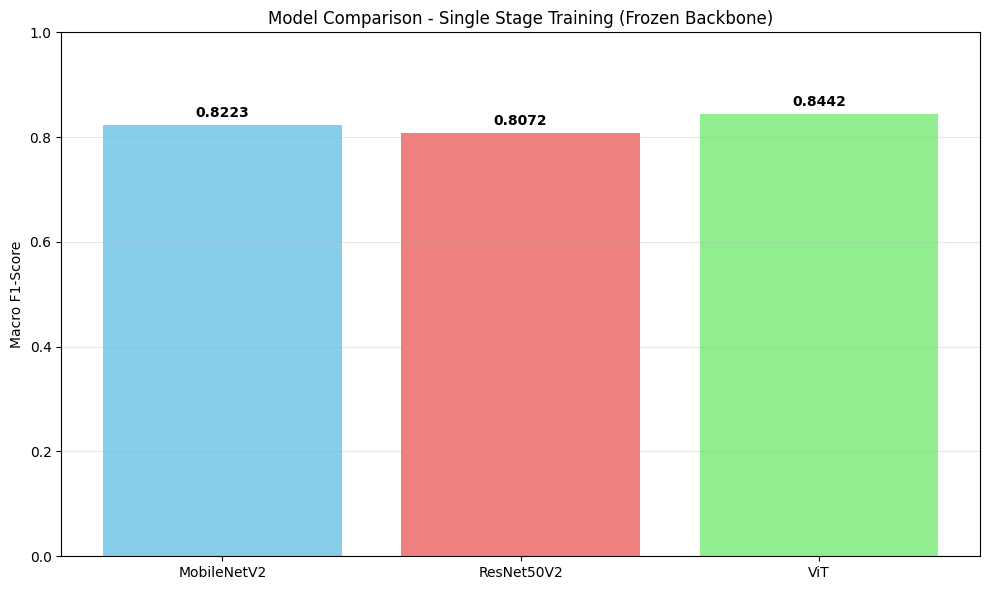


 Final Baseline Comparison:
MobileNetV2:  0.8223
ResNet50V2:   0.8072
ViT:          0.8442

 Best performing model: ViT (0.8442)


In [20]:
models = ['MobileNetV2', 'ResNet50V2', 'ViT']
f1_scores = [mobilenet_f1, resnet_f1, vit_f1]

plt.figure(figsize=(10, 6))
bars = plt.bar(models, f1_scores, color=['skyblue', 'lightcoral', 'lightgreen'])
plt.ylabel('Macro F1-Score')
plt.title('Model Comparison - Single Stage Training (Frozen Backbone)')
plt.ylim(0, 1)

# Add value labels
for bar, score in zip(bars, f1_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{score:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\n Final Baseline Comparison:")
print(f"MobileNetV2:  {mobilenet_f1:.4f}")
print(f"ResNet50V2:   {resnet_f1:.4f}")
print(f"ViT:          {vit_f1:.4f}")

# Determine winner
best_model = models[np.argmax(f1_scores)]
best_score = max(f1_scores)
print(f"\n Best performing model: {best_model} ({best_score:.4f})")

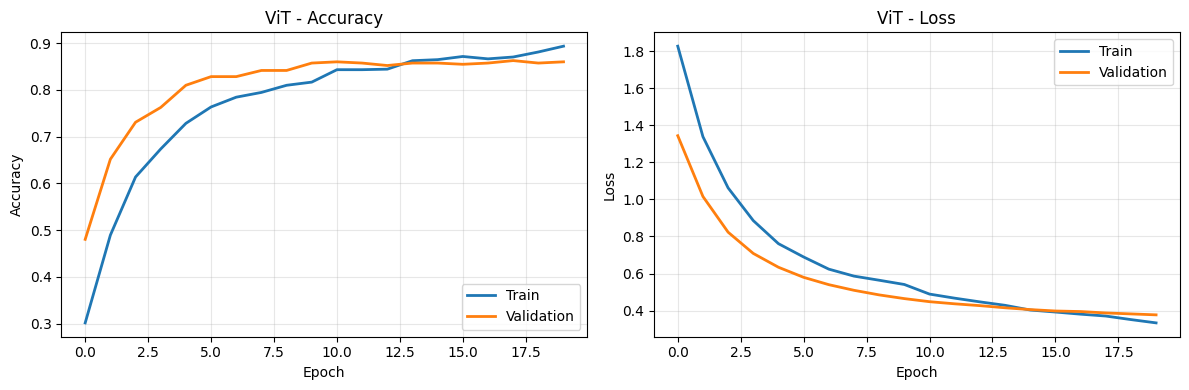

In [21]:
def plot_vit_training(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title('ViT - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title('ViT - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_vit_training(history_vit)

In [22]:
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/waste_classification_baselines/'
os.makedirs(save_dir, exist_ok=True)

mobilenet_model.save(f'{save_dir}/mobilenetv2_baseline.h5')
resnet_model.save(f'{save_dir}/resnet50v2_baseline.h5')
vit_model.save(f'{save_dir}/vit_baseline.keras')  # native Keras format

print(f" Models saved to {save_dir}")
print("Baseline experiment complete!")

Mounted at /content/drive


 Models saved to /content/drive/MyDrive/waste_classification_baselines/
Baseline experiment complete!
